In [1]:

!pip install pandas numpy scipy scikit-learn pyarrow matplotlib seaborn


In [2]:

import pandas as pd
import numpy as np
import scipy
import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)


All libraries imported successfully!
Pandas version: 2.2.3


In [3]:

import os

os.makedirs("bronze", exist_ok=True)
os.makedirs("silver", exist_ok=True)
os.makedirs("gold", exist_ok=True)

print("Data Lake folders created successfully!")

print(os.listdir())


Data Lake folders created successfully!
['.config', 'silver', 'bronze', 'gold', 'sample_data']


In [7]:

import requests
import zipfile
import os

url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

with open("book-crossings.zip", "wb") as f:
    f.write(response.content)

os.makedirs("raw_data", exist_ok=True)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("raw_data")

print("Dataset downloaded and extracted successfully!")
print("\nFiles inside raw_data:")

for file in os.listdir("raw_data"):
    print(file)


Dataset downloaded and extracted successfully!

Files inside raw_data:
BX-Book-Ratings.csv
BX-Books.csv
BX-Users.csv


In [8]:

for file in os.listdir("raw_data"):
    path = os.path.join("raw_data", file)
    print(file, "->", os.path.getsize(path), "bytes")


BX-Book-Ratings.csv -> 30682276 bytes
BX-Books.csv -> 77787439 bytes
BX-Users.csv -> 12284157 bytes


In [10]:

import pandas as pd
import csv

users = pd.read_csv(
    "raw_data/BX-Users.csv",
    sep=";",
    encoding="latin-1"
)

books = pd.read_csv(
    "raw_data/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    engine="python",
    on_bad_lines="warn"
)

ratings = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1"
)

print("All three datasets loaded!")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)


/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 815: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 1679: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 2531: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 2640: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 3236: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 3256: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 4906: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarning: Skipping line 6452: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_838/3393697263.py:10: ParserWarnin

All three datasets loaded!
Users: (278858, 3)
Books: (270491, 8)
Ratings: (1149780, 3)


In [12]:

file_path = "raw_data/BX-Books.csv"

with open(file_path, "r", encoding="latin-1") as f:
    for i in range(10):
        print(f"Line {i+1}: {f.readline().strip()}")


Line 1: "ISBN";"Book-Title";"Book-Author";"Year-Of-Publication";"Publisher";"Image-URL-S";"Image-URL-M";"Image-URL-L"
Line 2: "0195153448";"Classical Mythology";"Mark P. O. Morford";"2002";"Oxford University Press";"http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg"
Line 3: "0002005018";"Clara Callan";"Richard Bruce Wright";"2001";"HarperFlamingo Canada";"http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg"
Line 4: "0060973129";"Decision in Normandy";"Carlo D'Este";"1991";"HarperPerennial";"http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg"
Line 5: "0374157065";"Flu: The Story of the 

In [13]:

with open(file_path, "r", encoding="latin-1") as f:
    for i, line in enumerate(f, start=1):
        if i == 6:
            print("Problematic line:")
            print(line)
            print("\nNumber of semicolons:", line.count(";"))
            break


Problematic line:
"0393045218";"The Mummies of Urumchi";"E. J. W. Barber";"1999";"W. W. Norton &amp; Company";"http://images.amazon.com/images/P/0393045218.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0393045218.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0393045218.01.LZZZZZZZ.jpg"


Number of semicolons: 8


In [14]:

import csv

file_path = "raw_data/BX-Books.csv"

with open(file_path, "r", encoding="latin-1", newline="") as f:
    reader = csv.reader(f, delimiter=";", quotechar='"')

    for i, row in enumerate(reader):
        print(f"Line {i+1}: {len(row)} columns")
        if i < 6:
            print(row)
        if i == 10:
            break


Line 1: 8 columns
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
Line 2: 8 columns
['0195153448', 'Classical Mythology', 'Mark P. O. Morford', '2002', 'Oxford University Press', 'http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg', 'http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg', 'http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg']
Line 3: 8 columns
['0002005018', 'Clara Callan', 'Richard Bruce Wright', '2001', 'HarperFlamingo Canada', 'http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg', 'http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg', 'http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg']
Line 4: 8 columns
['0060973129', 'Decision in Normandy', "Carlo D'Este", '1991', 'HarperPerennial', 'http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg', 'http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg', 'http://images.amazon.com/images

In [15]:

import csv

file_path = "raw_data/BX-Books.csv"

bad_rows = []
total_rows = 0

with open(file_path, "r", encoding="latin-1", newline="") as f:
    reader = csv.reader(f, delimiter=";", quotechar='"')

    header = next(reader)

    for row_num, row in enumerate(reader, start=2):
        total_rows += 1

        if len(row) != len(header):
            bad_rows.append((row_num, len(row), row[:5]))

print("Total records:", total_rows)
print("Expected columns:", len(header))
print("Malformed records:", len(bad_rows))

print("\nFirst 10 malformed records:")
for row in bad_rows[:10]:
    print(row)


Total records: 271379
Expected columns: 8
Malformed records: 22

First 10 malformed records:
(6452, 9, ['0735201994', 'Peterman Rides Again: Adventures Continue with the Real \\J. Peterman\\" Through Life &amp', ' the Catalog Business"', 'John Peterman', '2000'])
(43667, 10, ['0330482750', 'Three Novels: \\A Strange and Sublime Address\\"', ' \\"Afternoon Raag\\"', '\\"Freedom Song\\""', 'Amit Chaudhuri'])
(51751, 9, ['0413326608', 'Upon my word!: More stories from \\My word!\\" a panel game devised by Edward J. Mason &amp', ' Tony Shryane"', 'Frank Muir', '1974'])
(92038, 9, ['0440500702', 'Schrodinger\'s Cat Trilogy : \\The Universe Next Door\\", \\"The Trick Top Hat\\", &amp', ' \\"The Homing Pigeons\\""', 'ROBERT A. WILSON', '1988'])
(104319, 9, ['0373166982', 'Please Say \\I Do\\"  (Three Weddings &amp', ' A Hurricane) (Harlequin American Romance, No 698)"', 'Karen T. Whittenburg', '1997'])
(121768, 9, ['0894805959', 'The Best of the Journal of Irreproducible Results: \\Improbable

In [16]:

import csv

file_path = "raw_data/BX-Books.csv"

bad_rows_fixed = []
total_rows_fixed = 0

with open(file_path, "r", encoding="latin-1", newline="") as f:
    reader = csv.reader(
        f,
        delimiter=";",
        quotechar='"',
        escapechar="\\"
    )

    header = next(reader)

    for row_num, row in enumerate(reader, start=2):
        total_rows_fixed += 1

        if len(row) != len(header):
            bad_rows_fixed.append((row_num, len(row)))

print("Total records:", total_rows_fixed)
print("Expected columns:", len(header))
print("Malformed records remaining:", len(bad_rows_fixed))
print("First malformed records:", bad_rows_fixed[:10])


Total records: 271379
Expected columns: 8
Malformed records remaining: 0
First malformed records: []


In [17]:

import pandas as pd
import csv

# Load Users
users = pd.read_csv(
    "raw_data/BX-Users.csv",
    sep=";",
    encoding="latin-1"
)

# Load Books with escape character handling
books = pd.read_csv(
    "raw_data/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    escapechar="\\",
    engine="python"
)

# Load Ratings
ratings = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1"
)

print("All datasets loaded successfully!")

print("\nDataset Shapes:")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

print("\nColumn Names:")
print("Users:", users.columns.tolist())
print("Books:", books.columns.tolist())
print("Ratings:", ratings.columns.tolist())


All datasets loaded successfully!

Dataset Shapes:
Users: (278858, 3)
Books: (271379, 8)
Ratings: (1149780, 3)

Column Names:
Users: ['User-ID', 'Location', 'Age']
Books: ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
Ratings: ['User-ID', 'ISBN', 'Book-Rating']


In [18]:

from datetime import datetime, timezone

ingestion_time = datetime.now(timezone.utc)

users["ingestion_timestamp"] = ingestion_time
books["ingestion_timestamp"] = ingestion_time
ratings["ingestion_timestamp"] = ingestion_time

print("Ingestion timestamps added successfully!")

display(users.head(2))


Ingestion timestamps added successfully!


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NaN,2026-11-26 05:03:19.725361+00:00
1,2,"stockton, california, usa",18.0,2026-11-26 05:03:19.725361+00:00


In [19]:

users.to_parquet("bronze/users.parquet", index=False)
books.to_parquet("bronze/books.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze Layer created successfully!")

print("\nFiles saved:")
print(os.listdir("bronze"))


Bronze Layer created successfully!

Files saved:
['books.parquet', 'ratings.parquet', 'users.parquet']


In [20]:

bronze_users = pd.read_parquet("bronze/users.parquet")
bronze_books = pd.read_parquet("bronze/books.parquet")
bronze_ratings = pd.read_parquet("bronze/ratings.parquet")

print("BRONZE LAYER VERIFICATION")

print("\nUsers:", bronze_users.shape)
print("Books:", bronze_books.shape)
print("Ratings:", bronze_ratings.shape)

print("\nTimestamp verification:")
print("Users:", "ingestion_timestamp" in bronze_users.columns)
print("Books:", "ingestion_timestamp" in bronze_books.columns)
print("Ratings:", "ingestion_timestamp" in bronze_ratings.columns)

print("\nBronze folder:", os.listdir("bronze"))


BRONZE LAYER VERIFICATION

Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)

Timestamp verification:
Users: True
Books: True
Ratings: True

Bronze folder: ['books.parquet', 'ratings.parquet', 'users.parquet']


In [21]:

import pandas as pd
import numpy as np

# Read data from Bronze layer
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded successfully!")


Bronze datasets loaded successfully!


In [22]:

datasets = {
    "Users": users,
    "Books": books,
    "Ratings": ratings
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name.upper())
    print("=" * 50)

    print("\nShape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())



USERS

Shape: (278858, 4)

Data Types:
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

BOOKS

Shape: (271379, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                  int64
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M     

### 2.2 Shape, Data Types and Missing Values

- Users: [Findings about missing values and data types].
- Books: [Findings about missing values and data types].
- Ratings: [Findings about missing values and data types].

Action: Missing values and incorrect data types will be handled
appropriately in the Silver layer.

In [23]:

# Count each rating value
rating_counts = ratings["Book-Rating"].value_counts().sort_index()

print("Rating Distribution:")
display(rating_counts)

# Count explicit and implicit ratings
zero_ratings = (ratings["Book-Rating"] == 0).sum()
explicit_ratings = ((ratings["Book-Rating"] >= 1) &
                    (ratings["Book-Rating"] <= 10)).sum()

print("\nTotal Ratings:", len(ratings))
print("Zero Ratings:", zero_ratings)
print("Explicit Ratings (1-10):", explicit_ratings)

print("\nPercentage of Zero Ratings:",
      round(zero_ratings / len(ratings) * 100, 2), "%")


Rating Distribution:


,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736



Total Ratings: 1149780
Zero Ratings: 716109
Explicit Ratings (1-10): 433671

Percentage of Zero Ratings: 62.28 %


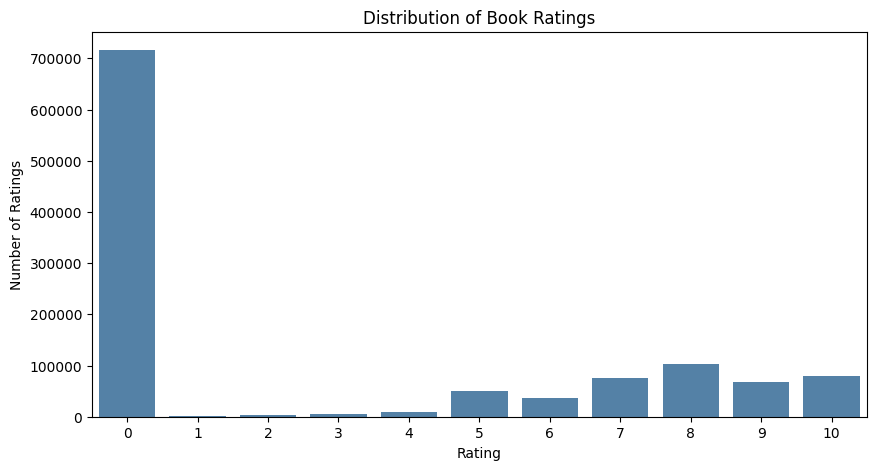

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=ratings,
    x="Book-Rating",
    color="steelblue"
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()


### Rating Distribution

The dataset contains ratings from 0 to 10.
There are [X] ratings with value 0, representing [Y]% of all ratings.
Zero ratings do not represent explicit user feedback.

Action: Remove zero ratings in the Silver layer and retain
only ratings between 1 and 10.

In [25]:

# Basic age statistics
print("USER AGE ANALYSIS")

print("\nAge Data Type:", users["Age"].dtype)

print("\nAge Statistics:")
print(users["Age"].describe())

print("\nMissing Ages:", users["Age"].isnull().sum())

print("Ages Below 5:", (users["Age"] < 5).sum())

print("Ages Above 100:", (users["Age"] > 100).sum())

print("Unique Ages:", users["Age"].nunique())


USER AGE ANALYSIS

Age Data Type: float64

Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing Ages: 110762
Ages Below 5: 882
Ages Above 100: 366
Unique Ages: 165


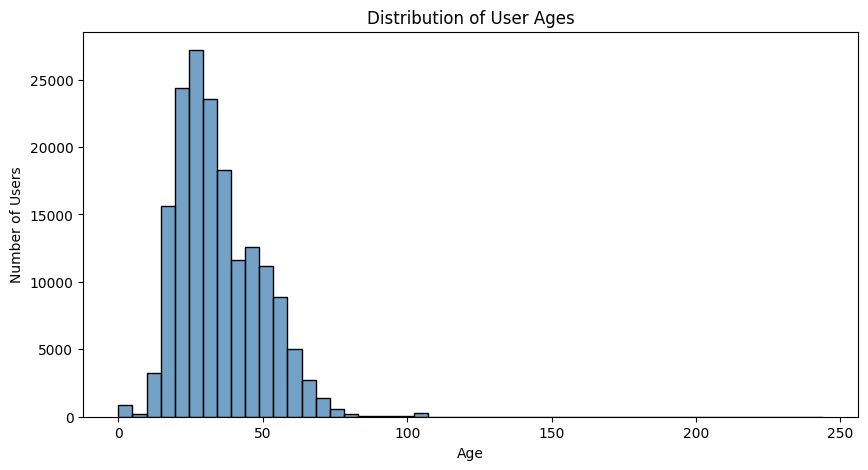

In [26]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    users["Age"].dropna(),
    bins=50,
    color="steelblue"
)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()


In [27]:

print("BOOK PUBLICATION YEAR ANALYSIS")

print("\nData Type:", books["Year-Of-Publication"].dtype)

print("\nPublication Year Statistics:")
print(books["Year-Of-Publication"].describe())

print("\nMissing Years:",
      books["Year-Of-Publication"].isnull().sum())

print("Year 0 Count:",
      (books["Year-Of-Publication"] == 0).sum())

print("Future Years Count:",
      (books["Year-Of-Publication"] > 2026).sum())

print("\nMost Common Publication Years:")
print(books["Year-Of-Publication"].value_counts().head(15))


BOOK PUBLICATION YEAR ANALYSIS

Data Type: int64

Publication Year Statistics:
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Missing Years: 0
Year 0 Count: 4619
Future Years Count: 11

Most Common Publication Years:
Year-Of-Publication
2002    17628
1999    17432
2001    17360
2000    17235
1998    15767
1997    14892
2003    14359
1996    14031
1995    13548
1994    11796
1993    10602
1992     9906
1991     9389
1990     8661
1989     7937
Name: count, dtype: int64


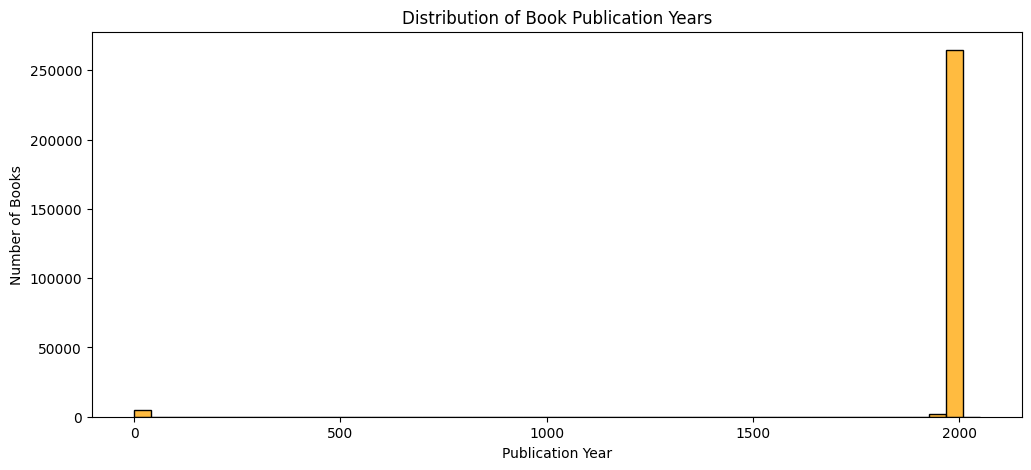

In [28]:

plt.figure(figsize=(12, 5))

sns.histplot(
    books["Year-Of-Publication"].dropna(),
    bins=50,
    color="orange"
)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.show()


### User Age Distribution

- Missing ages: [X]
- Ages below 5: [X]
- Ages above 100: [X]

Action: Invalid ages will be converted to null,
and missing ages will be filled with the median.

### Book Publication Year Distribution

- Missing years: [X]
- Publication year 0: [X]
- Future publication years: [X]

Action: Invalid publication years will be converted to null.

In [29]:

# Count ratings given by each user
user_rating_counts = ratings.groupby("User-ID").size()

print("USER RATING STATISTICS")
print(user_rating_counts.describe())

print("\nUsers with 1 rating:",
      (user_rating_counts == 1).sum())

print("Users with fewer than 10 ratings:",
      (user_rating_counts < 10).sum())

print("Users with 10 or more ratings:",
      (user_rating_counts >= 10).sum())

print("\nTop 10 users by number of ratings:")
print(user_rating_counts.sort_values(ascending=False).head(10))


USER RATING STATISTICS
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Users with 1 rating: 59166
Users with fewer than 10 ratings: 92186
Users with 10 or more ratings: 13097

Top 10 users by number of ratings:
User-ID
11676     13602
198711     7550
153662     6109
98391      5891
35859      5850
212898     4785
278418     4533
76352      3367
110973     3100
235105     3067
dtype: int64


In [30]:

# Count ratings received by each book
book_rating_counts = ratings.groupby("ISBN").size()

print("BOOK RATING STATISTICS")
print(book_rating_counts.describe())

print("\nBooks with 1 rating:",
      (book_rating_counts == 1).sum())

print("Books with fewer than 10 ratings:",
      (book_rating_counts < 10).sum())

print("Books with 10 or more ratings:",
      (book_rating_counts >= 10).sum())

print("\nTop 10 books by number of ratings:")
print(book_rating_counts.sort_values(ascending=False).head(10))


BOOK RATING STATISTICS
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Books with 1 rating: 197045
Books with fewer than 10 ratings: 322237
Books with 10 or more ratings: 18319

Top 10 books by number of ratings:
ISBN
0971880107    2502
0316666343    1295
0385504209     883
0060928336     732
0312195516     723
044023722X     647
0679781587     639
0142001740     615
067976402X     614
0671027360     586
dtype: int64


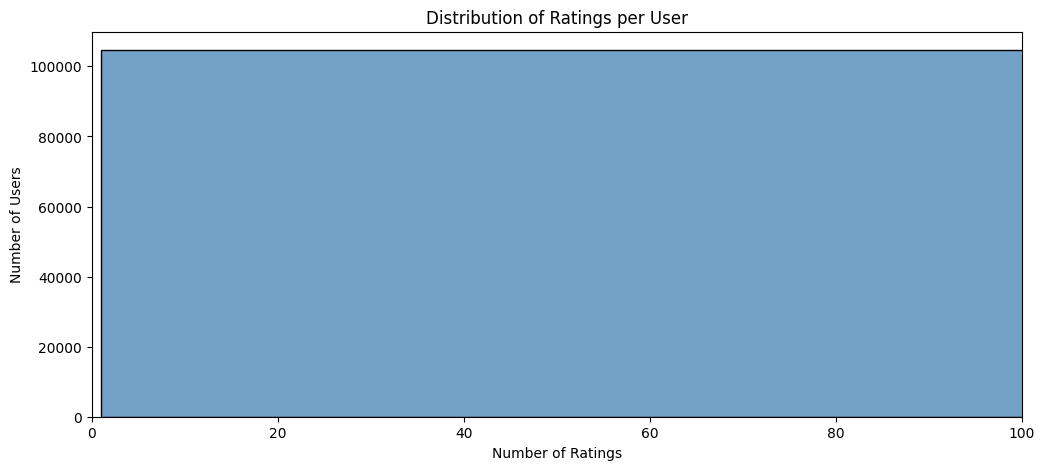

In [31]:

plt.figure(figsize=(12, 5))

sns.histplot(
    user_rating_counts,
    bins=50,
    color="steelblue"
)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.xlim(0, 100)

plt.show()


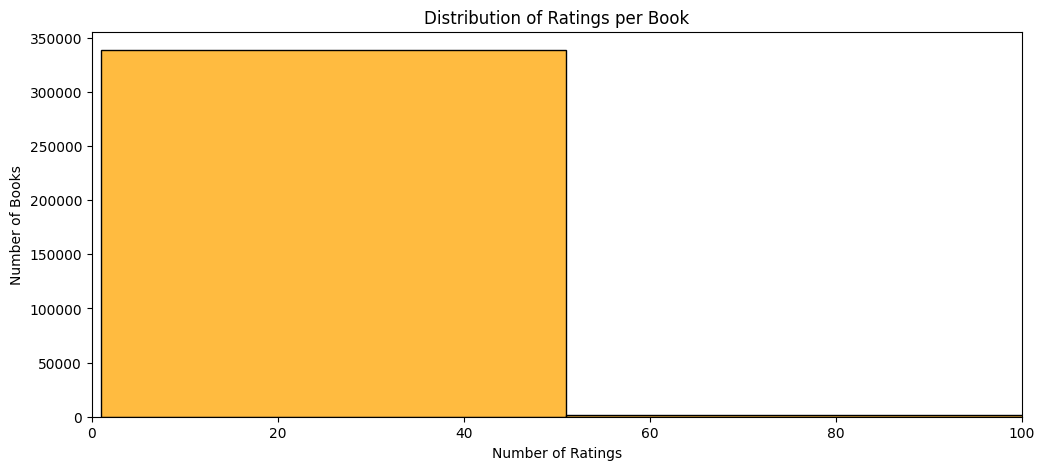

In [32]:

plt.figure(figsize=(12, 5))

sns.histplot(
    book_rating_counts,
    bins=50,
    color="orange"
)

plt.title("Distribution of Ratings per Book")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Books")
plt.xlim(0, 100)

plt.show()


In [33]:

# Total unique users and books
num_users = ratings["User-ID"].nunique()
num_books = ratings["ISBN"].nunique()

# Total possible user-book combinations
total_possible = num_users * num_books

# Actual rating records
actual_ratings = len(ratings)

# Calculate sparsity
sparsity = (1 - actual_ratings / total_possible) * 100

print("MATRIX SPARSITY ANALYSIS")

print("Unique Users:", num_users)
print("Unique Books:", num_books)
print("Total Possible User-Book Pairs:", total_possible)
print("Actual Rating Records:", actual_ratings)

print("\nMatrix Sparsity:", round(sparsity, 4), "%")
print("Matrix Density:", round(100 - sparsity, 4), "%")


MATRIX SPARSITY ANALYSIS
Unique Users: 105283
Unique Books: 340556
Total Possible User-Book Pairs: 35854757348
Actual Rating Records: 1149780

Matrix Sparsity: 99.9968 %
Matrix Density: 0.0032 %


### Ratings per User and Book

- Most users have relatively few ratings.
- Most books also receive relatively few ratings.
- A minimum rating threshold will be applied in Silver to
  retain users and books with sufficient interaction history.

### Matrix Sparsity

- The user-book rating matrix is highly sparse.
- A large percentage of possible user-book combinations
  have no rating.
- A sparse matrix representation will be used in Gold
  to save memory and support efficient similarity calculations.

In [35]:

# Load original Bronze data
users_silver = pd.read_parquet("bronze/users.parquet")
books_silver = pd.read_parquet("bronze/books.parquet")
ratings_silver = pd.read_parquet("bronze/ratings.parquet")

# Create independent working copies
users_silver = users_silver.copy()
books_silver = books_silver.copy()
ratings_silver = ratings_silver.copy()

print("Silver working copies created!")

print("\nBefore Cleaning:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Silver working copies created!

Before Cleaning:
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [36]:

# Count duplicate records
print("DUPLICATE RECORDS BEFORE CLEANING")

print("Duplicate users:", users_silver.duplicated().sum())
print("Duplicate books:", books_silver.duplicated().sum())
print("Duplicate ratings:", ratings_silver.duplicated().sum())

# Remove duplicates
users_silver = users_silver.drop_duplicates()
books_silver = books_silver.drop_duplicates()
ratings_silver = ratings_silver.drop_duplicates()

print("\nAfter removing duplicates:")

print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


DUPLICATE RECORDS BEFORE CLEANING
Duplicate users: 0
Duplicate books: 0
Duplicate ratings: 0

After removing duplicates:
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [37]:

# Convert ratings to numeric values
ratings_silver["Book-Rating"] = pd.to_numeric(
    ratings_silver["Book-Rating"],
    errors="coerce"
)

# Count ratings before cleaning
print("Ratings before cleaning:", len(ratings_silver))

print("Zero ratings:",
      (ratings_silver["Book-Rating"] == 0).sum())

print("Invalid ratings:",
      (~ratings_silver["Book-Rating"].between(1, 10)).sum())

# Keep only ratings between 1 and 10
ratings_silver = ratings_silver[
    ratings_silver["Book-Rating"].between(1, 10)
].copy()

print("\nRatings after cleaning:", len(ratings_silver))

print("\nRemaining rating values:")
print(sorted(ratings_silver["Book-Rating"].unique()))


Ratings before cleaning: 1149780
Zero ratings: 716109
Invalid ratings: 716109

Ratings after cleaning: 433671

Remaining rating values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


### 3.1 Duplicate Removal and Rating Cleaning

- Removed duplicate records from Users, Books and Ratings.
- Removed zero ratings because they represent implicit
  interactions rather than explicit feedback.
- Retained only ratings between 1 and 10.

These changes ensure that the recommendation model uses
valid and non-duplicated explicit user feedback.

In [38]:

# Convert Age to numeric
users_silver["Age"] = pd.to_numeric(
    users_silver["Age"],
    errors="coerce"
)

# Replace invalid ages with NaN
users_silver.loc[
    (users_silver["Age"] < 5) | (users_silver["Age"] > 100),
    "Age"
] = np.nan

# Calculate median age
median_age = users_silver["Age"].median()

# Fill missing ages with median
users_silver["Age"] = users_silver["Age"].fillna(median_age)

print("Age cleaning completed!")

print("\nMedian Age:", median_age)
print("Remaining Missing Ages:", users_silver["Age"].isnull().sum())

print("\nAge Statistics:")
print(users_silver["Age"].describe())


Age cleaning completed!

Median Age: 32.0
Remaining Missing Ages: 0

Age Statistics:
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [39]:

# Split Location into three columns
location_parts = users_silver["Location"].str.split(
    ",",
    n=2,
    expand=True
)

# Assign the extracted values
users_silver["City"] = location_parts[0]
users_silver["State"] = location_parts[1]
users_silver["Country"] = location_parts[2]

# Remove extra spaces
users_silver["City"] = users_silver["City"].str.strip()
users_silver["State"] = users_silver["State"].str.strip()
users_silver["Country"] = users_silver["Country"].str.strip()

# Drop original Location column
users_silver.drop(columns=["Location"], inplace=True)

print("Location splitting completed!")

display(users_silver[["City", "State", "Country"]].head(10))


Location splitting completed!


,City,State,Country
0,nyc,new york,usa
1,stockton,california,usa
2,moscow,yukon territory,russia
3,porto,v.n.gaia,portugal
4,farnborough,hants,united kingdom
5,santa monica,california,usa
6,washington,dc,usa
7,timmins,ontario,canada
8,germantown,tennessee,usa
9,albacete,wisconsin,spain


### 3.2 User Age and Location Cleaning

- Converted Age into numeric format.
- Replaced ages below 5 and above 100 with null values.
- Filled missing ages using the median age.
- Split Location into City, State and Country columns.
- Removed the original Location column.

In [40]:

print("USER DATA AFTER CLEANING")

print("\nColumns:")
print(users_silver.columns.tolist())

print("\nMissing Values:")
print(users_silver.isnull().sum())

print("\nAge Range:")
print(users_silver["Age"].min(), "to", users_silver["Age"].max())

display(users_silver.head())


USER DATA AFTER CLEANING

Columns:
['User-ID', 'Age', 'ingestion_timestamp', 'City', 'State', 'Country']

Missing Values:
User-ID                0
Age                    0
ingestion_timestamp    0
City                   0
State                  1
Country                2
dtype: int64

Age Range:
5.0 to 100.0


,User-ID,Age,ingestion_timestamp,City,State,Country
0,1,32.0,2026-11-26 05:03:19.725361+00:00,nyc,new york,usa
1,2,18.0,2026-11-26 05:03:19.725361+00:00,stockton,california,usa
2,3,32.0,2026-11-26 05:03:19.725361+00:00,moscow,yukon territory,russia
3,4,17.0,2026-11-26 05:03:19.725361+00:00,porto,v.n.gaia,portugal
4,5,32.0,2026-11-26 05:03:19.725361+00:00,farnborough,hants,united kingdom


In [41]:

# Convert publication year to numeric
books_silver["Year-Of-Publication"] = pd.to_numeric(
    books_silver["Year-Of-Publication"],
    errors="coerce"
)

# Count invalid years before cleaning
print("Publication year 0:",
      (books_silver["Year-Of-Publication"] == 0).sum())

print("Future publication years:",
      (books_silver["Year-Of-Publication"] > 2026).sum())

print("Missing publication years:",
      books_silver["Year-Of-Publication"].isnull().sum())


Publication year 0: 4619
Future publication years: 11
Missing publication years: 0


In [42]:

# Replace year 0 and future years with NaN
books_silver.loc[
    (books_silver["Year-Of-Publication"] == 0) |
    (books_silver["Year-Of-Publication"] > 2026),
    "Year-Of-Publication"
] = np.nan

print("Publication years cleaned!")

print("\nRemaining invalid years:",
      ((books_silver["Year-Of-Publication"] == 0) |
       (books_silver["Year-Of-Publication"] > 2026)).sum())

print("\nPublication year statistics:")
print(books_silver["Year-Of-Publication"].describe())


Publication years cleaned!

Remaining invalid years: 0

Publication year statistics:
count    266749.000000
mean       1993.687894
std           8.321821
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2026.000000
Name: Year-Of-Publication, dtype: float64


### 3.3 Publication Year Cleaning

- Converted publication years into numeric format.
- Replaced publication year 0 with null.
- Replaced future publication years with null.
- Preserved valid publication years.

In [43]:

print("Missing values before text cleaning:")
print(books_silver.isnull().sum())

print("\nBook text columns:")
display(
    books_silver[
        ["ISBN", "Book-Title", "Book-Author", "Publisher"]
    ].head(10)
)


Missing values before text cleaning:
ISBN                      0
Book-Title                0
Book-Author               2
Year-Of-Publication    4630
Publisher                 2
Image-URL-S               0
Image-URL-M               0
Image-URL-L               0
ingestion_timestamp       0
dtype: int64

Book text columns:


,ISBN,Book-Title,Book-Author,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,HarperFlamingo Canada
2,0060973129,Decision in Normandy,Carlo D'Este,HarperPerennial
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,Farrar Straus Giroux
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,W. W. Norton &amp; Company
5,0399135782,The Kitchen God's Wife,Amy Tan,Putnam Pub Group
6,0425176428,What If?: The World's Foremost Military Histor...,Robert Cowley,Berkley Publishing Group
7,0671870432,PLEADING GUILTY,Scott Turow,Audioworks
8,0679425608,Under the Black Flag: The Romance and the Real...,David Cordingly,Random House
9,074322678X,Where You'll Find Me: And Other Stories,Ann Beattie,Scribner


In [44]:

text_columns = ["Book-Title", "Book-Author", "Publisher"]

for col in text_columns:
    books_silver[col] = (
        books_silver[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

print("Text columns cleaned successfully!")

display(
    books_silver[
        ["ISBN", "Book-Title", "Book-Author", "Publisher"]
    ].head(10)
)


Text columns cleaned successfully!


,ISBN,Book-Title,Book-Author,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'Este,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,W. W. Norton &Amp; Company
5,0399135782,The Kitchen God'S Wife,Amy Tan,Putnam Pub Group
6,0425176428,What If?: The World'S Foremost Military Histor...,Robert Cowley,Berkley Publishing Group
7,0671870432,Pleading Guilty,Scott Turow,Audioworks
8,0679425608,Under The Black Flag: The Romance And The Real...,David Cordingly,Random House
9,074322678X,Where You'Ll Find Me: And Other Stories,Ann Beattie,Scribner


In [45]:

image_columns = [
    "Image-URL-S",
    "Image-URL-M",
    "Image-URL-L"
]

books_silver.drop(
    columns=image_columns,
    inplace=True
)

print("Image URL columns removed!")

print("\nRemaining columns:")
print(books_silver.columns.tolist())


Image URL columns removed!

Remaining columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']


In [46]:

print("BOOKS AFTER CLEANING")

print("\nShape:", books_silver.shape)

print("\nMissing values:")
print(books_silver.isnull().sum())

display(books_silver.head())


BOOKS AFTER CLEANING

Shape: (271379, 6)

Missing values:
ISBN                      0
Book-Title                0
Book-Author               2
Year-Of-Publication    4630
Publisher                 2
ingestion_timestamp       0
dtype: int64


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002.0,Oxford University Press,2026-11-26 05:03:19.725361+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001.0,Harperflamingo Canada,2026-11-26 05:03:19.725361+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991.0,Harperperennial,2026-11-26 05:03:19.725361+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999.0,Farrar Straus Giroux,2026-11-26 05:03:19.725361+00:00
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999.0,W. W. Norton &Amp; Company,2026-11-26 05:03:19.725361+00:00



### 3.4 Book Text Cleaning

- Removed extra whitespace from book titles, authors and publishers.
- Standardized text using title case.
- Removed unnecessary image URL columns.
- Preserved ISBN as the unique book identifier.
- Missing text values are retained as missing rather than inventing information.


In [47]:

# Get all valid user IDs and book ISBNs
valid_user_ids = set(users_silver["User-ID"])
valid_book_isbns = set(books_silver["ISBN"])

# Find ratings with missing users or books
invalid_users = ~ratings_silver["User-ID"].isin(valid_user_ids)
invalid_books = ~ratings_silver["ISBN"].isin(valid_book_isbns)

print("REFERENTIAL INTEGRITY CHECK")

print("Ratings with nonexistent users:", invalid_users.sum())
print("Ratings with nonexistent books:", invalid_books.sum())

print("Ratings with either invalid user or book:",
      (invalid_users | invalid_books).sum())

print("\nTotal ratings before filtering:", len(ratings_silver))


REFERENTIAL INTEGRITY CHECK
Ratings with nonexistent users: 0
Ratings with nonexistent books: 49819
Ratings with either invalid user or book: 49819

Total ratings before filtering: 433671


In [48]:

# Keep only ratings whose user and book both exist
ratings_silver = ratings_silver[
    ratings_silver["User-ID"].isin(valid_user_ids) &
    ratings_silver["ISBN"].isin(valid_book_isbns)
].copy()

print("Referential integrity cleaning completed!")

print("Ratings remaining:", len(ratings_silver))


Referential integrity cleaning completed!
Ratings remaining: 383852


In [49]:

user_counts = ratings_silver.groupby("User-ID").size()
book_counts = ratings_silver.groupby("ISBN").size()

print("Users with at least 10 ratings:",
      (user_counts >= 10).sum())

print("Users with fewer than 10 ratings:",
      (user_counts < 10).sum())

print("\nBooks with at least 10 ratings:",
      (book_counts >= 10).sum())

print("Books with fewer than 10 ratings:",
      (book_counts < 10).sum())


Users with at least 10 ratings: 6589
Users with fewer than 10 ratings: 61503

Books with at least 10 ratings: 5444
Books with fewer than 10 ratings: 144398


In [50]:

min_ratings = 10

previous_size = -1

while previous_size != len(ratings_silver):

    previous_size = len(ratings_silver)

    # Keep users with at least 10 ratings
    user_counts = ratings_silver.groupby("User-ID").size()
    valid_users = user_counts[user_counts >= min_ratings].index

    ratings_silver = ratings_silver[
        ratings_silver["User-ID"].isin(valid_users)
    ].copy()

    # Keep books with at least 10 ratings
    book_counts = ratings_silver.groupby("ISBN").size()
    valid_books = book_counts[book_counts >= min_ratings].index

    ratings_silver = ratings_silver[
        ratings_silver["ISBN"].isin(valid_books)
    ].copy()

print("Minimum rating threshold applied!")

print("\nFinal rating count:", len(ratings_silver))
print("Remaining unique users:", ratings_silver["User-ID"].nunique())
print("Remaining unique books:", ratings_silver["ISBN"].nunique())


Minimum rating threshold applied!

Final rating count: 41456
Remaining unique users: 1820
Remaining unique books: 2030


In [51]:

# Keep only users and books present in the filtered ratings
users_silver = users_silver[
    users_silver["User-ID"].isin(ratings_silver["User-ID"])
].copy()

books_silver = books_silver[
    books_silver["ISBN"].isin(ratings_silver["ISBN"])
].copy()

print("Final Silver Dataset Shapes:")

print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Final Silver Dataset Shapes:
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [52]:

final_user_counts = ratings_silver.groupby("User-ID").size()
final_book_counts = ratings_silver.groupby("ISBN").size()

print("Minimum user ratings:", final_user_counts.min())
print("Minimum book ratings:", final_book_counts.min())

print("\nAll users satisfy threshold:",
      (final_user_counts >= 10).all())

print("All books satisfy threshold:",
      (final_book_counts >= 10).all())


Minimum user ratings: 10
Minimum book ratings: 10

All users satisfy threshold: True
All books satisfy threshold: True


In [53]:

users_silver.to_parquet("silver/users.parquet", index=False)
books_silver.to_parquet("silver/books.parquet", index=False)
ratings_silver.to_parquet("silver/ratings.parquet", index=False)

print("Silver Layer saved successfully!")

print("\nSilver folder contents:")
print(os.listdir("silver"))


Silver Layer saved successfully!

Silver folder contents:
['books.parquet', 'ratings.parquet', 'users.parquet']



### 3.5 Referential Integrity and Rating Threshold

- Removed ratings referencing nonexistent users or books.
- Selected a minimum rating threshold of 10.
- Retained users with at least 10 ratings.
- Retained books with at least 10 ratings.
- Applied iterative filtering until both conditions were satisfied.
- Removed users and books that no longer had ratings.

The threshold reduces extremely sparse interactions and provides
more reliable data for item-based collaborative filtering.


In [54]:

# Load cleaned Silver datasets
users_silver = pd.read_parquet("silver/users.parquet")
books_silver = pd.read_parquet("silver/books.parquet")
ratings_silver = pd.read_parquet("silver/ratings.parquet")

print("Silver datasets loaded successfully!")

print("\nDataset Shapes:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Silver datasets loaded successfully!

Dataset Shapes:
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [55]:

from scipy.sparse import csr_matrix, save_npz, load_npz
import numpy as np
import os

# Create mappings for books and users
book_ids = ratings_silver["ISBN"].unique()
user_ids = ratings_silver["User-ID"].unique()

# Map ISBN and User-ID to matrix positions
book_to_idx = {book: idx for idx, book in enumerate(book_ids)}
user_to_idx = {user: idx for idx, user in enumerate(user_ids)}

# Convert IDs into row and column indices
row_indices = ratings_silver["ISBN"].map(book_to_idx)
col_indices = ratings_silver["User-ID"].map(user_to_idx)

# Get actual rating values
rating_values = ratings_silver["Book-Rating"].values

# Create sparse matrix
rating_matrix = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(book_ids), len(user_ids))
)

print("Sparse Rating Matrix Created!")

print("Matrix Shape:", rating_matrix.shape)
print("Number of Actual Ratings:", rating_matrix.nnz)
print("Matrix Type:", type(rating_matrix))


Sparse Rating Matrix Created!
Matrix Shape: (2030, 1820)
Number of Actual Ratings: 41456
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>


In [56]:

# Save sparse matrix
save_npz("gold/rating_matrix.npz", rating_matrix)

# Save book and user ID mappings
np.save("gold/book_ids.npy", book_ids)
np.save("gold/user_ids.npy", user_ids)

print("Rating matrix and ID mappings saved successfully!")
print(os.listdir("gold"))


Rating matrix and ID mappings saved successfully!
['user_ids.npy', 'rating_matrix.npz', 'book_ids.npy']


In [57]:

book_lookup = books_silver[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()

print("Book Lookup Table:")
display(book_lookup.head())

# Save lookup table
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

print("Book lookup table saved!")


Book Lookup Table:


,ISBN,Book-Title,Book-Author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton


Book lookup table saved!


In [58]:

user_aggregates = (
    ratings_silver
    .groupby("User-ID")["Book-Rating"]
    .agg(
        average_rating="mean",
        number_of_ratings="count"
    )
    .reset_index()
)

display(user_aggregates.head())

user_aggregates.to_parquet(
    "gold/user_aggregates.parquet",
    index=False
)

print("User aggregates saved!")


,User-ID,average_rating,number_of_ratings
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17


User aggregates saved!


In [59]:

book_aggregates = (
    ratings_silver
    .groupby("ISBN")["Book-Rating"]
    .agg(
        average_rating="mean",
        number_of_ratings="count"
    )
    .reset_index()
)

display(book_aggregates.head())

book_aggregates.to_parquet(
    "gold/book_aggregates.parquet",
    index=False
)

print("Book aggregates saved!")


,ISBN,average_rating,number_of_ratings
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


Book aggregates saved!


In [60]:

print("GOLD LAYER VERIFICATION")

print("\nRating Matrix:")
print("Shape:", rating_matrix.shape)
print("Non-zero values:", rating_matrix.nnz)

print("\nBook Lookup:", book_lookup.shape)
print("User Aggregates:", user_aggregates.shape)
print("Book Aggregates:", book_aggregates.shape)

print("\nFiles in Gold folder:")
for file in os.listdir("gold"):
    print(file)


GOLD LAYER VERIFICATION

Rating Matrix:
Shape: (2030, 1820)
Non-zero values: 41456

Book Lookup: (2030, 3)
User Aggregates: (1820, 3)
Book Aggregates: (2030, 3)

Files in Gold folder:
user_aggregates.parquet
user_ids.npy
rating_matrix.npz
book_aggregates.parquet
book_ids.npy
book_lookup.parquet


In [61]:

import pandas as pd
import numpy as np

from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors

# Load sparse rating matrix
rating_matrix = load_npz("gold/rating_matrix.npz")

# Load ID mappings
book_ids = np.load("gold/book_ids.npy", allow_pickle=True)
user_ids = np.load("gold/user_ids.npy", allow_pickle=True)

# Load book lookup table
book_lookup = pd.read_parquet("gold/book_lookup.parquet")

# Load aggregates
user_aggregates = pd.read_parquet("gold/user_aggregates.parquet")
book_aggregates = pd.read_parquet("gold/book_aggregates.parquet")

print("Gold data loaded successfully!")

print("Rating Matrix:", rating_matrix.shape)
print("Books:", len(book_ids))
print("Users:", len(user_ids))


Gold data loaded successfully!
Rating Matrix: (2030, 1820)
Books: 2030
Users: 1820


In [62]:

# Create the Nearest Neighbors model
model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11,
    n_jobs=-1
)

# Train the model on book rating vectors
model.fit(rating_matrix)

print("Cosine similarity model trained successfully!")


Cosine similarity model trained successfully!


In [63]:

def find_similar_books(book_title, n=10):

    # Find the book using its title
    matches = book_lookup[
        book_lookup["Book-Title"].str.lower() == book_title.lower()
    ]

    if matches.empty:
        print("Book not found!")
        return pd.DataFrame()

    # Get ISBN of the selected book
    isbn = matches.iloc[0]["ISBN"]

    # Find its position in the matrix
    book_idx = np.where(book_ids == isbn)[0][0]

    # Get similar books
    distances, indices = model.kneighbors(
        rating_matrix[book_idx],
        n_neighbors=min(n + 1, len(book_ids))
    )

    results = []

    for distance, idx in zip(distances[0], indices[0]):

        # Skip the original book
        if idx == book_idx:
            continue

        similar_isbn = book_ids[idx]

        book_info = book_lookup[
            book_lookup["ISBN"] == similar_isbn
        ].iloc[0]

        similarity = 1 - distance

        results.append({
            "Book-Title": book_info["Book-Title"],
            "Book-Author": book_info["Book-Author"],
            "Similarity": round(float(similarity), 4)
        })

        if len(results) == n:
            break

    return pd.DataFrame(results)


In [64]:

find_similar_books("Harry Potter and the Sorcerer's Stone")


Book not found!


""


In [65]:

display(book_lookup[["Book-Title", "Book-Author"]].head(20))


,Book-Title,Book-Author
0,The Testament,John Grisham
1,Beloved (Plume Contemporary Fiction),Toni Morrison
2,Wild Animus,Rich Shapero
3,Airframe,Michael Crichton
4,Timeline,Michael Crichton
5,To Kill A Mockingbird,Harper Lee
6,Seabiscuit: An American Legend,Laura Hillenbrand
7,I'Ll Be Seeing You,Mary Higgins Clark
8,From The Corner Of His Eye,Dean Koontz
9,Isle Of Dogs,Patricia Cornwell


In [66]:

ratings_silver = pd.read_parquet("silver/ratings.parquet")

print("Silver ratings loaded!")
print("Total ratings:", len(ratings_silver))


Silver ratings loaded!
Total ratings: 41456


In [67]:

def recommend(user_id, n=10):

    # Get all books rated by the user
    user_ratings = ratings_silver[
        ratings_silver["User-ID"] == user_id
    ]

    if user_ratings.empty:
        print("User not found or has no ratings!")
        return pd.DataFrame()

    # Select books rated highly (7 or above)
    liked_books = user_ratings[
        user_ratings["Book-Rating"] >= 7
    ]

    if liked_books.empty:
        print("User has not rated any book 7 or above!")
        return pd.DataFrame()

    # Books already rated by the user
    already_read = set(user_ratings["ISBN"])

    # Store recommendation scores
    scores = {}

    # Process each highly rated book
    for _, row in liked_books.iterrows():

        isbn = row["ISBN"]
        rating = row["Book-Rating"]

        # Find position of the book in the rating matrix
        book_idx = np.where(book_ids == isbn)[0]

        if len(book_idx) == 0:
            continue

        book_idx = book_idx[0]

        # Find similar books
        distances, indices = model.kneighbors(
            rating_matrix[book_idx],
            n_neighbors=min(11, len(book_ids))
        )

        # Calculate weighted similarity scores
        for distance, idx in zip(distances[0], indices[0]):

            recommended_isbn = book_ids[idx]

            # Skip the original book
            if recommended_isbn == isbn:
                continue

            # Skip books already rated by the user
            if recommended_isbn in already_read:
                continue

            similarity = max(0, 1 - distance)

            score = similarity * rating

            scores[recommended_isbn] = (
                scores.get(recommended_isbn, 0) + score
            )

    if not scores:
        print("No recommendations found!")
        return pd.DataFrame()

    # Sort books by recommendation score
    ranked_books = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    # Convert ISBNs into readable book information
    results = []

    for isbn, score in ranked_books:

        book_info = book_lookup[
            book_lookup["ISBN"] == isbn
        ].iloc[0]

        results.append({
            "ISBN": isbn,
            "Book-Title": book_info["Book-Title"],
            "Book-Author": book_info["Book-Author"],
            "Recommendation-Score": round(score, 4)
        })

    return pd.DataFrame(results)


In [68]:

# Count highly rated books for each user
high_rating_counts = (
    ratings_silver[ratings_silver["Book-Rating"] >= 7]
    .groupby("User-ID")
    .size()
    .sort_values(ascending=False)
)

print("Users with the most highly rated books:")
display(high_rating_counts.head(10))


Users with the most highly rated books:


,0
User-ID,
11676,736
16795,200
104636,180
153662,164
95359,161
98391,136
60244,132
258534,109
78973,106


In [69]:

test_user = int(high_rating_counts.index[0])

print("Testing User ID:", test_user)

print("\nRecommended Books:")
display(recommend(test_user, n=10))


Testing User ID: 11676

Recommended Books:


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0440167531,Palomino,Danielle Steel,36.8367
1,0373270976,"Night Shield (Intimate Moments, 1027)",Nora Roberts,31.6602
2,0842332251,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,23.2592
3,0842329285,The Indwelling: The Beast Takes Possession (Le...,Tim Lahaye,22.0152
4,0670839531,Needful Things: The Last Castle Rock Story,Stephen King,21.2773
5,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,21.1420
6,0399149848,Birthright,Nora Roberts,21.0330
7,0440168724,A Perfect Stranger,Danielle Steel,21.0125
8,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,20.3768
9,0842329269,Apollyon: The Destroyer Is Unleashed (Left Beh...,Jerry Jenkins,19.8089


In [70]:

# Select three users who have rated at least one book 7 or above
test_users = high_rating_counts.head(3).index.tolist()

print("Selected Test Users:", test_users)


Selected Test Users: [11676, 16795, 104636]


In [71]:

def demo_user(user_id):

    print("\n" + "=" * 80)
    print("USER ID:", user_id)
    print("=" * 80)

    # Get books rated highly by this user
    liked = ratings_silver[
        (ratings_silver["User-ID"] == user_id) &
        (ratings_silver["Book-Rating"] >= 7)
    ].sort_values("Book-Rating", ascending=False)

    print("\nBOOKS RATED HIGHLY BY USER:")

    liked_display = liked.merge(
        book_lookup,
        on="ISBN",
        how="left"
    )

    display(
        liked_display[
            ["Book-Title", "Book-Author", "Book-Rating"]
        ].head(10)
    )

    # Generate recommendations
    print("\nTOP 10 RECOMMENDED BOOKS:")

    recommendations = recommend(user_id, n=10)

    display(recommendations)

    return recommendations


In [72]:

all_recommendations = {}

for user_id in test_users:
    all_recommendations[user_id] = demo_user(user_id)



USER ID: 11676

BOOKS RATED HIGHLY BY USER:


,Book-Title,Book-Author,Book-Rating
0,The Time Traveler'S Wife,Audrey Niffenegger,10
1,The Time Traveler'S Wife (Today Show Book Club...,Audrey Niffenegger,10
2,Message From Nam,Danielle Steel,10
3,Mixed Blessings,Danielle Steel,10
4,Echoes,Maeve Binchy,10
5,Remembrance,Danielle Steel,10
6,Illusions: The Adventures Of A Reluctant Messiah,Richard Bach,10
7,The Alchemist: A Fable About Following Your Dream,Paulo Coelho,10
8,The Secret Garden,Frances Hodgson Burnett,10
9,The Reptile Room (A Series Of Unfortunate Even...,Lemony Snicket,10



TOP 10 RECOMMENDED BOOKS:


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0440167531,Palomino,Danielle Steel,36.8367
1,0373270976,"Night Shield (Intimate Moments, 1027)",Nora Roberts,31.6602
2,0842332251,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,23.2592
3,0842329285,The Indwelling: The Beast Takes Possession (Le...,Tim Lahaye,22.0152
4,0670839531,Needful Things: The Last Castle Rock Story,Stephen King,21.2773
5,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,21.1420
6,0399149848,Birthright,Nora Roberts,21.0330
7,0440168724,A Perfect Stranger,Danielle Steel,21.0125
8,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,20.3768
9,0842329269,Apollyon: The Destroyer Is Unleashed (Left Beh...,Jerry Jenkins,19.8089



USER ID: 16795

BOOKS RATED HIGHLY BY USER:


,Book-Title,Book-Author,Book-Rating
0,The Dive From Clausen'S Pier (Alex Awards),Ann Packer,10
1,How Reading Changed My Life (Library Of Contem...,Anna Quindlen,10
2,The Lovely Bones: A Novel,Alice Sebold,10
3,The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10
4,The Secret Life Of Bees,Sue Monk Kidd,10
5,Life Of Pi,Yann Martel,10
6,The Samurai'S Garden : A Novel,Gail Tsukiyama,10
7,The Liar'S Club: A Memoir,Mary Karr,10
8,Skipping Christmas,John Grisham,10
9,Skipping Christmas,John Grisham,10


... (2 outputs left out)


USER ID: 104636

BOOKS RATED HIGHLY BY USER:


,Book-Title,Book-Author,Book-Rating
0,Where The Sidewalk Ends : Poems And Drawings,Shel Silverstein,10
1,Bridge To Terabithia,Katherine Paterson,10
2,"The Lion, The Witch, And The Wardrobe (The Chr...",C. S. Lewis,10
3,Little House On The Prairie,Laura Ingalls Wilder,10
4,Charlotte'S Web (Trophy Newbery),E. B. White,10
5,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,10
6,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,10
7,Secrets,Danielle Steel,10
8,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,10
9,Eyes Of A Child,Richard North Patterson,10



TOP 10 RECOMMENDED BOOKS:


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0671701231,The Anastasia Syndrome,Mary Higgins Clark,24.7621
1,042511984X,The Face Of Fear,Dean R. Koontz,20.5438
2,0312983867,Hard Eight : A Stephanie Plum Novel (A Stephan...,Janet Evanovich,17.5934
3,0312265867,To The Nines: A Stephanie Plum Novel,Janet Evanovich,15.3307
4,0553285785,Public Secrets,Nora Roberts,13.9380
5,0440221471,The Runaway Jury,John Grisham,11.4459
6,038531292X,The Gift,Danielle Steel,11.0974
7,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,9.9139
8,0671729454,If There Be Thorns (Dollanganger),V.C. Andrews,9.0601
9,0380732661,The Ritual Bath (Peter Decker &Amp; Rina Lazar...,Faye Kellerman,8.7857


In [73]:

print("RECOMMENDATION SANITY CHECK")

for user_id, recs in all_recommendations.items():

    already_read = set(
        ratings_silver.loc[
            ratings_silver["User-ID"] == user_id,
            "ISBN"
        ]
    )

    recommended = set(recs["ISBN"]) if not recs.empty else set()

    print("\nUser:", user_id)

    print("Recommendation count:", len(recommended))

    print("Already read books recommended:",
          len(already_read.intersection(recommended)))

    print("Scores in descending order:",
          recs["Recommendation-Score"].is_monotonic_decreasing
          if not recs.empty else "No recommendations")


RECOMMENDATION SANITY CHECK

User: 11676
Recommendation count: 10
Already read books recommended: 0
Scores in descending order: True

User: 16795
Recommendation count: 10
Already read books recommended: 0
Scores in descending order: True

User: 104636
Recommendation count: 10
Already read books recommended: 0
Scores in descending order: True


In [74]:

print("=" * 55)
print("FINAL PROJECT VALIDATION")
print("=" * 55)

print("\n1. DATA LAKE")
print("Bronze files:", len(os.listdir("bronze")))
print("Silver files:", len(os.listdir("silver")))
print("Gold files:", len(os.listdir("gold")))

print("\n2. SILVER DATA")
print("Users:", len(users_silver))
print("Books:", len(books_silver))
print("Ratings:", len(ratings_silver))

print("\n3. GOLD DATA")
print("Rating Matrix:", rating_matrix.shape)
print("Non-zero ratings:", rating_matrix.nnz)

print("\n4. DATA INTEGRITY")
print("Duplicate user-book pairs:",
      ratings_silver.duplicated(
          subset=["User-ID", "ISBN"]
      ).sum())

print("All users have at least 10 ratings:",
      (ratings_silver.groupby("User-ID").size() >= 10).all())

print("All books have at least 10 ratings:",
      (ratings_silver.groupby("ISBN").size() >= 10).all())

print("\n5. RECOMMENDER")
print("Tested users:", len(all_recommendations))
print("All users received 10 recommendations:",
      all(len(x) == 10 for x in all_recommendations.values()))

print("\nFINAL VALIDATION COMPLETED")


FINAL PROJECT VALIDATION

1. DATA LAKE
Bronze files: 3
Silver files: 3
Gold files: 6

2. SILVER DATA
Users: 1820
Books: 2030
Ratings: 41456

3. GOLD DATA
Rating Matrix: (2030, 1820)
Non-zero ratings: 41456

4. DATA INTEGRITY
Duplicate user-book pairs: 0
All users have at least 10 ratings: True
All books have at least 10 ratings: True

5. RECOMMENDER
Tested users: 3
All users received 10 recommendations: True

FINAL VALIDATION COMPLETED


In [75]:

print("FINAL BRONZE EDA SUMMARY")

print("\n1. DATASET SHAPES")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

print("\n2. MISSING VALUES")
for name, df in {
    "Users": users,
    "Books": books,
    "Ratings": ratings
}.items():
    print(f"\n{name}:")
    print(df.isnull().sum())

print("\n3. RATING DISTRIBUTION")
print(ratings["Book-Rating"].value_counts().sort_index())
print("Zero ratings:", (ratings["Book-Rating"] == 0).sum())

print("\n4. AGE ANALYSIS")
print(users["Age"].describe())
print("Missing:", users["Age"].isnull().sum())
print("Below 5:", (users["Age"] < 5).sum())
print("Above 100:", (users["Age"] > 100).sum())

print("\n5. PUBLICATION YEARS")
print(books["Year-Of-Publication"].describe())
print("Year 0:", (books["Year-Of-Publication"] == 0).sum())
print("Future years:", (books["Year-Of-Publication"] > 2026).sum())

print("\n6. MATRIX SPARSITY")
u = ratings["User-ID"].nunique()
b = ratings["ISBN"].nunique()
possible = u * b

print("Unique users:", u)
print("Unique books:", b)
print("Actual rating records:", len(ratings))
print("Sparsity:", round((1 - len(ratings) / possible) * 100, 4), "%")


FINAL BRONZE EDA SUMMARY

1. DATASET SHAPES
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)

2. MISSING VALUES

Users:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

Books:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtype: int64

Ratings:
User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64

3. RATING DISTRIBUTION
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64
Zero ratings: 716109

4. AGE ANALYSIS
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%      


## 2. Exploratory Data Analysis (EDA)

### 2.1 Dataset Shape and Missing Values

- Users: 278,858 rows and 4 columns. The Age column contains 110,762 missing values.
- Books: 271,379 rows and 9 columns. Book-Author and Publisher each contain 2 missing values.
- Ratings: 1,149,780 rows and 4 columns, with no missing values.

Action: Missing ages will be handled using median imputation. Missing author and publisher information will be preserved as missing values.

### 2.2 Rating Distribution

- The dataset contains ratings from 0 to 10.
- There are 716,109 zero ratings, representing approximately 62.28% of all ratings.
- Zero ratings represent interactions without explicit feedback.
- The remaining ratings range from 1 to 10.

Action: Remove zero ratings and retain only explicit ratings between 1 and 10.

### 2.3 User Age Distribution

- There are 110,762 missing age values.
- The minimum age is 0 and the maximum age is 244.
- 882 users have ages below 5.
- 366 users have ages above 100.
- The median age is 32.

Action: Replace ages below 5 and above 100 with null values, then fill missing ages using the median.

### 2.4 Book Publication Year Distribution

- The publication year ranges from 0 to 2050.
- 4,619 books have publication year 0.
- 11 books have future publication years.
- The median publication year is 1995.

Action: Replace publication year 0 and future publication years with null values.

### 2.5 Ratings per User and Book

- Rating counts per user and per book were examined to understand the distribution of interactions.
- A minimum threshold of 10 ratings was selected to retain users and books with sufficient interaction history.

Action: Remove users and books with fewer than 10 ratings.

### 2.6 User-Book Matrix Sparsity

- Unique users: 105,283.
- Unique books: 340,556.
- Actual rating records: 1,149,780.
- Matrix sparsity: approximately 99.9968%.

Action: Use a sparse matrix representation in the Gold layer to reduce memory consumption and efficiently calculate book similarities.


In [76]:

print("USERS DATA TYPES")
print(users.dtypes)

print("\nBOOKS DATA TYPES")
print(books.dtypes)

print("\nRATINGS DATA TYPES")
print(ratings.dtypes)


USERS DATA TYPES
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

BOOKS DATA TYPES
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                  int64
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

RATINGS DATA TYPES
User-ID                              int64
ISBN                                object
Book-Rating                          int64
ingestion_timestamp    datetime64[us, UTC]
dtype: object


In [77]:

print("RATINGS PER USER")
print(user_rating_counts.describe())

print("\nRATINGS PER BOOK")
print(book_rating_counts.describe())

print("\nUsers with fewer than 10 ratings:",
      (user_rating_counts < 10).sum())

print("Books with fewer than 10 ratings:",
      (book_rating_counts < 10).sum())


RATINGS PER USER
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

RATINGS PER BOOK
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Users with fewer than 10 ratings: 92186
Books with fewer than 10 ratings: 322237


# Conclusion

In this assignment, we successfully developed a Book Recommendation System using the Book-Crossing dataset and the Medallion Data Lake architecture.

The project followed a structured Bronze-Silver-Gold data processing pipeline:

1. **Bronze Layer:** Ingested the original Users, Books, and Book-Ratings datasets, added ingestion timestamps, and stored them in Parquet format without performing data cleaning.

2. **Silver Layer:** Cleaned the datasets by removing duplicate records, filtering invalid ratings, handling missing and invalid user ages, correcting publication years, processing location and text columns, maintaining referential integrity, and applying a minimum rating threshold of 10.

3. **Gold Layer:** Prepared model-ready data by creating a sparse user-book rating matrix, a book lookup table, and user-level and book-level aggregates.

For the recommendation engine, we implemented **Item-Based Collaborative Filtering** using cosine similarity and Scikit-learn's `NearestNeighbors` algorithm.

The `recommend(user_id, n=10)` function generates personalized book recommendations based on a user's highly rated books. It ranks candidate books using similarity scores weighted by the user's ratings and excludes books the user has already rated.

Finally, we tested the recommendation system on three different users. Each user received 10 recommendations, and the sanity checks confirmed that previously rated books were not recommended.

This assignment demonstrated how raw data can be transformed into clean, model-ready data through a Medallion Data Lake pipeline and used to build a functional recommendation system.